# Chapter 24: Project: Stock Price Study

The programs from Chapter 24 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Returns, Volatility and Correlation

`returns.py`

In [1]:
import numpy as np
import pandas as pd

prices = pd.read_csv(
    "../data/prices.csv", parse_dates=["date"], index_col="date"
)
returns = prices.pct_change().dropna()

summary = pd.DataFrame(
    {
        "total return": prices.iloc[-1] / prices.iloc[0] - 1,
        "annual volatility": returns.std() * np.sqrt(252),
        "best day": returns.max(),
        "worst day": returns.min(),
    }
)
print(summary.round(3))
print()
print(returns.corr().round(2))

       total return  annual volatility  best day  worst day
ALDR          0.595              0.196     0.042     -0.038
BRKN          0.866              0.320     0.078     -0.053
CDLX          0.307              0.134     0.029     -0.028
INDEX         0.527              0.140     0.028     -0.021

       ALDR  BRKN  CDLX  INDEX
ALDR   1.00  0.31  0.35   0.56
BRKN   0.31  1.00  0.32   0.52
CDLX   0.35  0.32  1.00   0.59
INDEX  0.56  0.52  0.59   1.00


## Drawdown and Beta

`drawdown_beta.py`

In [2]:
import numpy as np
import pandas as pd

prices = pd.read_csv(
    "../data/prices.csv", parse_dates=["date"], index_col="date"
)
returns = prices.pct_change().dropna()

peak = prices.cummax()
drawdown = prices / peak - 1
print("largest fall from a previous high:")
print(drawdown.min().round(3).to_string())
print("deepest point for BRKN:", drawdown["BRKN"].idxmin().date())
print()

for ticker in ["ALDR", "BRKN", "CDLX"]:
    slope, _ = np.polyfit(returns["INDEX"], returns[ticker], 1)
    print(f"{ticker} beta against the index: {slope:.2f}")

largest fall from a previous high:
ALDR    -0.255
BRKN    -0.223
CDLX    -0.169
INDEX   -0.153
deepest point for BRKN: 2025-04-03

ALDR beta against the index: 0.78
BRKN beta against the index: 1.19
CDLX beta against the index: 0.57


## Growth of $100

`growth_chart.py`

Saved growth_chart.png


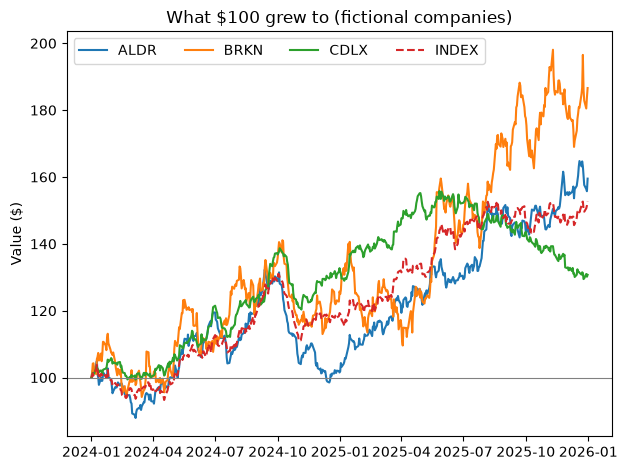

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

prices = pd.read_csv(
    "../data/prices.csv", parse_dates=["date"], index_col="date"
)
growth = 100 * prices / prices.iloc[0]  # $100 invested on day one

fig, ax = plt.subplots()
for column in growth.columns:
    style = "--" if column == "INDEX" else "-"
    ax.plot(growth.index, growth[column], style, label=column)
ax.axhline(100, color="gray", linewidth=0.8)
ax.set_title("What $100 grew to (fictional companies)")
ax.set_ylabel("Value ($)")
ax.legend(ncol=4)
fig.tight_layout()
fig.savefig("growth_chart.png")
print("Saved growth_chart.png")